# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Subscription Churn Dataset](https://www.kaggle.com/datasets/vedauv/subscription-churn-prediction-2026-20k-users?select=subscription_churn.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('subscription_churn.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,subscriber_id,country,plan,contract,tenure_months,monthly_price_usd,discount_pct,payment_method,primary_device,device_count,avg_weekly_hours,days_since_last_login,support_tickets_90d,recent_price_increase,autopay,referred_by_friend,nps_score,lifetime_value_usd,churned_90d
0,U000001,Australia,Standard,Annual,12,13.99,0,Card,Smart TV,2,2.9,2,1,0,1,0,5,360.80,0
1,U000002,Germany,Premium,Monthly,15,19.99,10,Card,Console,7,4.5,1,0,0,0,0,5,656.79,0
2,U000003,India,Basic,Annual,1,7.99,0,Gift card,Console,1,8.7,1,1,1,0,0,7,122.50,0
3,U000004,Other,Basic,Monthly,15,7.99,0,Card,Mobile,5,8.9,2,0,0,1,0,10,220.76,0
4,U000005,Germany,Basic,Monthly,21,7.99,0,Card,Smart TV,2,8.8,2,0,0,0,0,6,302.51,0


## last Five row

In [4]:
df.tail()

,subscriber_id,country,plan,contract,tenure_months,monthly_price_usd,discount_pct,payment_method,primary_device,device_count,avg_weekly_hours,days_since_last_login,support_tickets_90d,recent_price_increase,autopay,referred_by_friend,nps_score,lifetime_value_usd,churned_90d
19995,U019996,Other,Standard,Monthly,6,13.99,0,Card,Smart TV,1,0.9,0,0,0,0,0,5,340.53,0
19996,U019997,Brazil,Basic,Monthly,4,7.99,0,PayPal,Mobile,1,13.0,1,1,0,0,0,8,181.64,0
19997,U019998,India,Basic,Monthly,9,7.99,0,Card,Mobile,1,32.5,2,2,1,1,1,10,187.06,0
19998,U019999,USA,Standard,Monthly,6,13.99,0,Card,Mobile,2,4.0,1,0,0,1,0,6,356.87,0
19999,U020000,USA,Standard,Annual,38,13.99,0,Gift card,Mobile,1,7.3,1,1,0,1,0,10,731.09,0


## Shape of our dataset

In [5]:
df.shape

(20000, 19)

## List out all columns

In [6]:
df.columns

Index(['subscriber_id', 'country', 'plan', 'contract', 'tenure_months',
       'monthly_price_usd', 'discount_pct', 'payment_method', 'primary_device',
       'device_count', 'avg_weekly_hours', 'days_since_last_login',
       'support_tickets_90d', 'recent_price_increase', 'autopay',
       'referred_by_friend', 'nps_score', 'lifetime_value_usd', 'churned_90d'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

subscriber_id             object
country                   object
plan                      object
contract                  object
tenure_months              int64
monthly_price_usd        float64
discount_pct               int64
payment_method            object
primary_device            object
device_count               int64
avg_weekly_hours         float64
days_since_last_login      int64
support_tickets_90d        int64
recent_price_increase      int64
autopay                    int64
referred_by_friend         int64
nps_score                  int64
lifetime_value_usd       float64
churned_90d                int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   subscriber_id          20000 non-null  object 
 1   country                20000 non-null  object 
 2   plan                   20000 non-null  object 
 3   contract               20000 non-null  object 
 4   tenure_months          20000 non-null  int64  
 5   monthly_price_usd      20000 non-null  float64
 6   discount_pct           20000 non-null  int64  
 7   payment_method         20000 non-null  object 
 8   primary_device         20000 non-null  object 
 9   device_count           20000 non-null  int64  
 10  avg_weekly_hours       20000 non-null  float64
 11  days_since_last_login  20000 non-null  int64  
 12  support_tickets_90d    20000 non-null  int64  
 13  recent_price_increase  20000 non-null  int64  
 14  autopay                20000 non-null  int64  
 15  re

## Check Null Value

In [9]:
df.isnull().sum()

subscriber_id            0
country                  0
plan                     0
contract                 0
tenure_months            0
monthly_price_usd        0
discount_pct             0
payment_method           0
primary_device           0
device_count             0
avg_weekly_hours         0
days_since_last_login    0
support_tickets_90d      0
recent_price_increase    0
autopay                  0
referred_by_friend       0
nps_score                0
lifetime_value_usd       0
churned_90d              0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,tenure_months,monthly_price_usd,discount_pct,device_count,avg_weekly_hours,days_since_last_login,support_tickets_90d,recent_price_increase,autopay,referred_by_friend,nps_score,lifetime_value_usd,churned_90d
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000
mean,13.927000,12.901600,6.689000,2.309850,6.302280,4.556300,0.491050,0.245650,0.648800,0.117300,6.59915,332.525047,0.260000
std,13.536559,4.615414,9.491142,1.335789,4.990386,5.897861,0.704446,0.430483,0.477357,0.321785,1.94326,242.788264,0.438645
min,0.000000,7.990000,0.000000,1.000000,0.400000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,6.790000,0.000000
25%,4.000000,7.990000,0.000000,1.000000,3.100000,1.000000,0.000000,0.000000,0.000000,0.000000,5.00000,165.212500,0.000000
50%,10.000000,13.990000,0.000000,2.000000,4.900000,3.000000,0.000000,0.000000,1.000000,0.000000,7.00000,278.175000,0.000000
75%,19.000000,13.990000,10.000000,3.000000,7.900000,5.000000,1.000000,0.000000,1.000000,0.000000,8.00000,439.900000,1.000000
max,72.000000,19.990000,30.000000,8.000000,60.000000,90.000000,5.000000,1.000000,1.000000,1.000000,10.00000,1926.030000,1.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

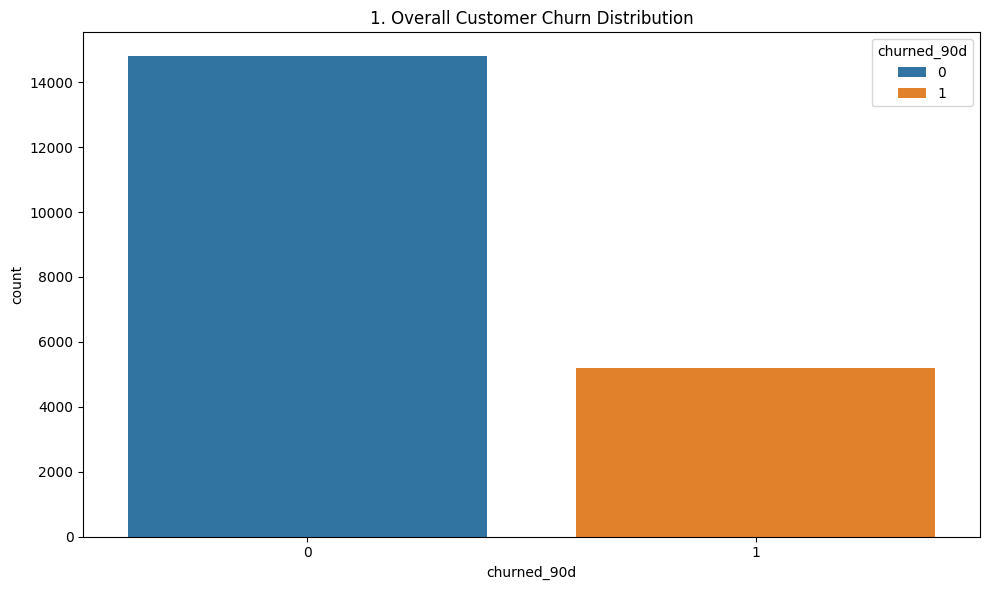

In [13]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='churned_90d', hue='churned_90d')
plt.title(f'{plot_no}. Overall Customer Churn Distribution')
show_fig()
plot_no += 1

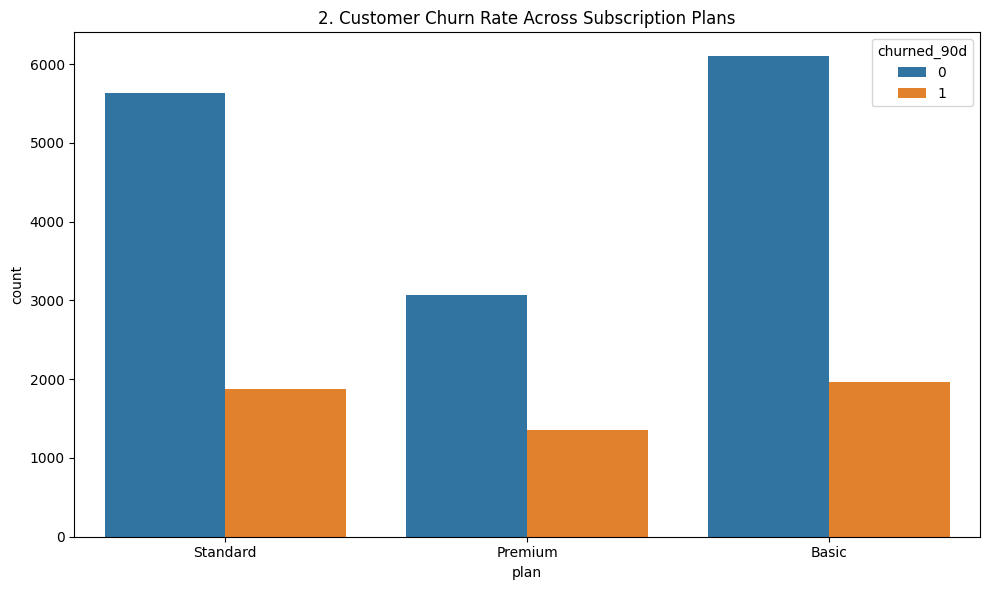

In [14]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='plan', hue='churned_90d')
plt.title(f'{plot_no}. Customer Churn Rate Across Subscription Plans')
show_fig()
plot_no += 1

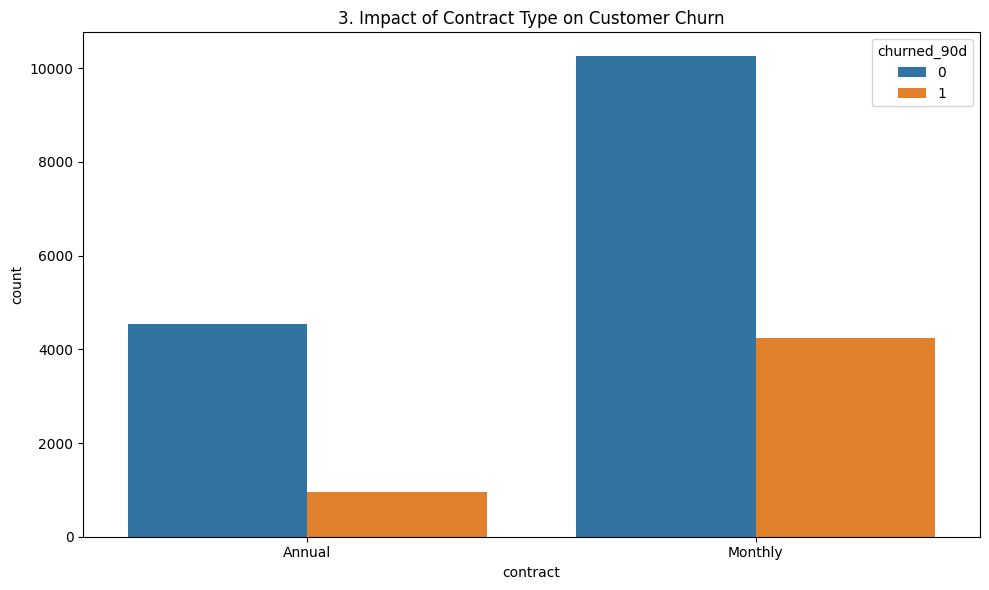

In [15]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='contract', hue='churned_90d')
plt.title(f'{plot_no}. Impact of Contract Type on Customer Churn')
show_fig()
plot_no += 1

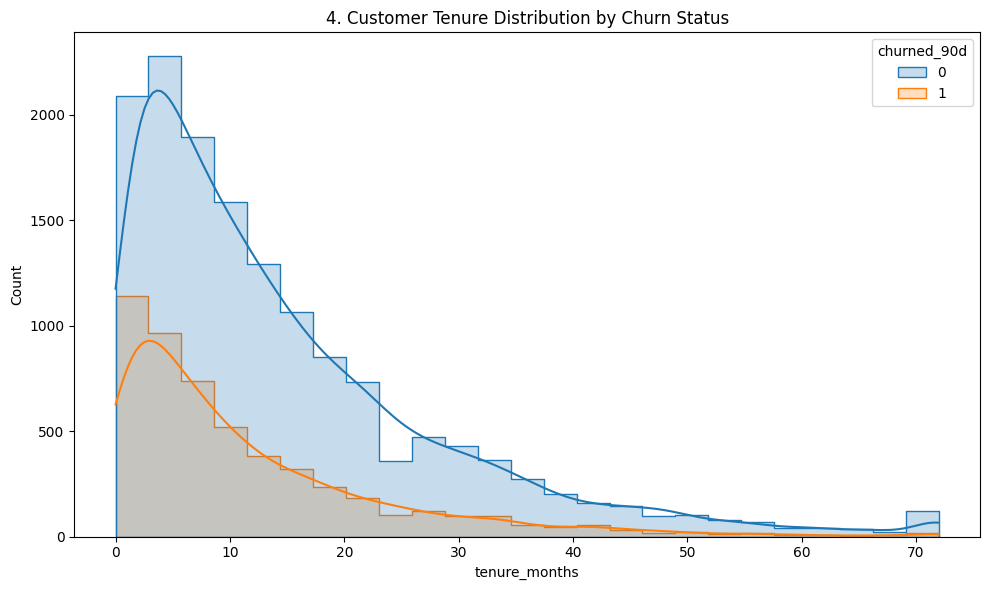

In [16]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='tenure_months', hue='churned_90d', kde=True, bins=25, element='step')
plt.title(f'{plot_no}. Customer Tenure Distribution by Churn Status')
show_fig()
plot_no += 1

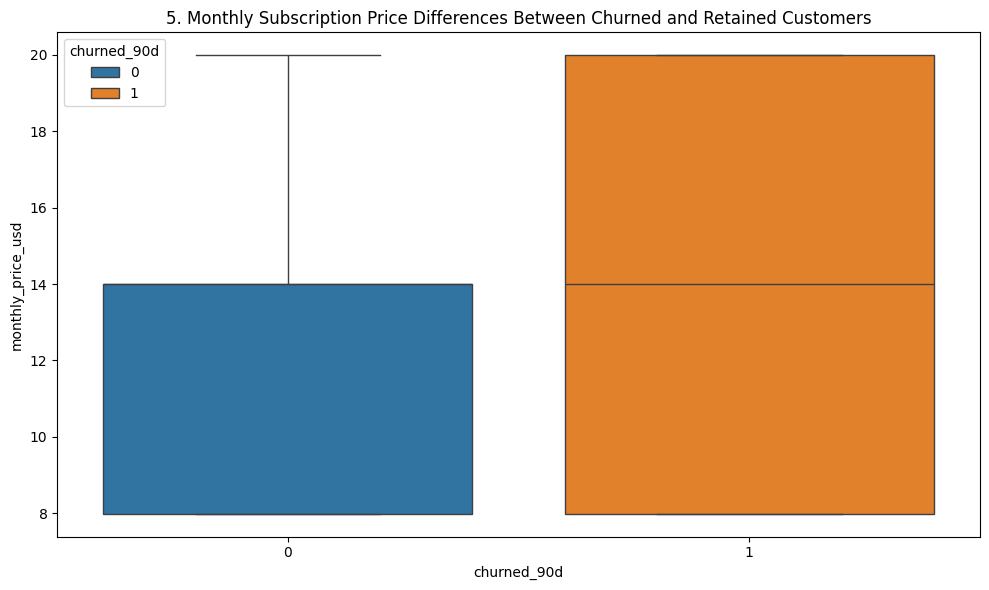

In [17]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='churned_90d', y='monthly_price_usd', hue='churned_90d')
plt.title(f'{plot_no}. Monthly Subscription Price Differences Between Churned and Retained Customers')
show_fig()
plot_no += 1

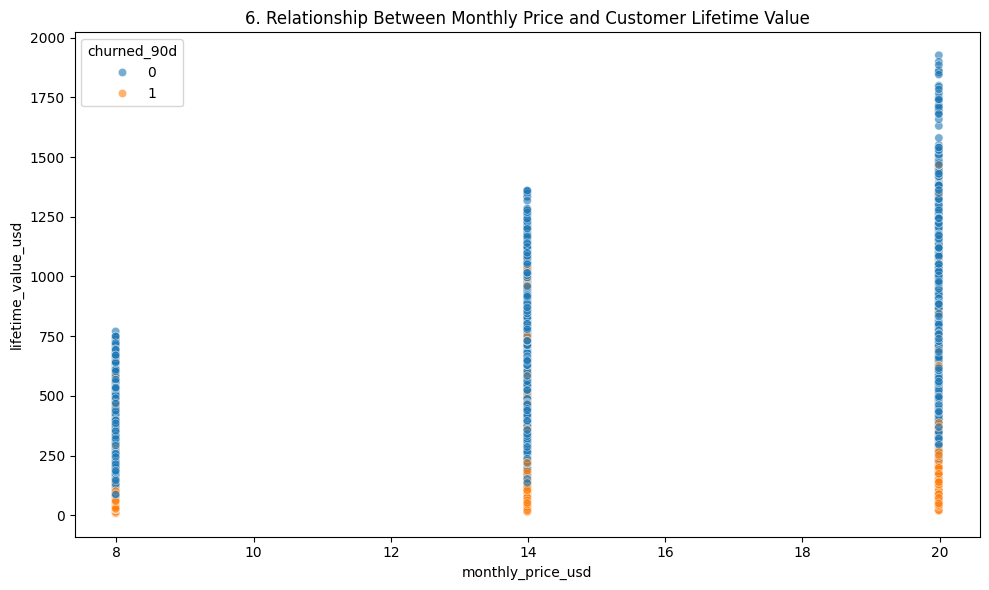

In [18]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='monthly_price_usd', y='lifetime_value_usd', hue='churned_90d', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Monthly Price and Customer Lifetime Value')
show_fig()
plot_no += 1

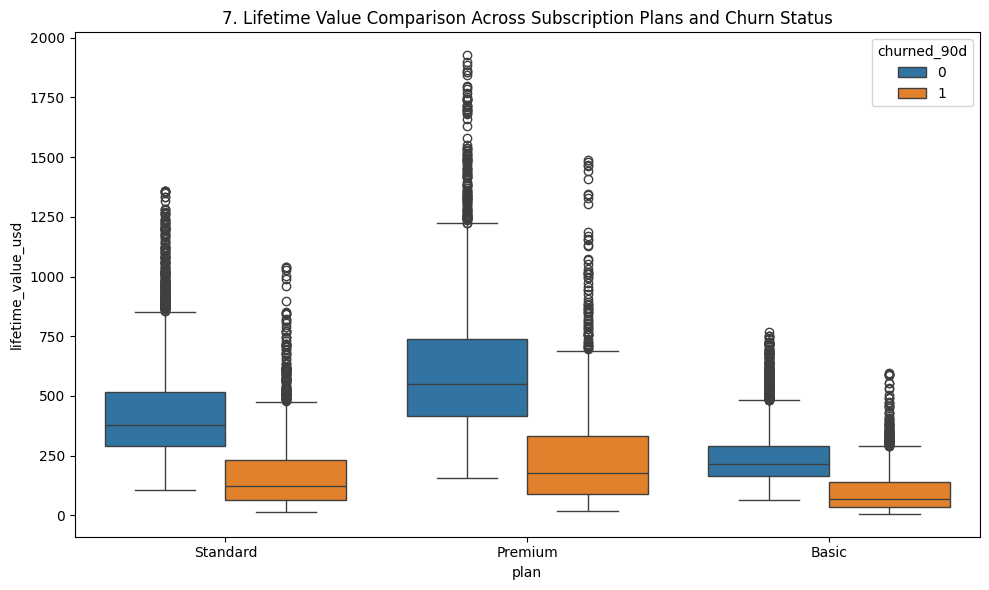

In [19]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='plan', y='lifetime_value_usd', hue='churned_90d')
plt.title(f'{plot_no}. Lifetime Value Comparison Across Subscription Plans and Churn Status')
show_fig()
plot_no += 1

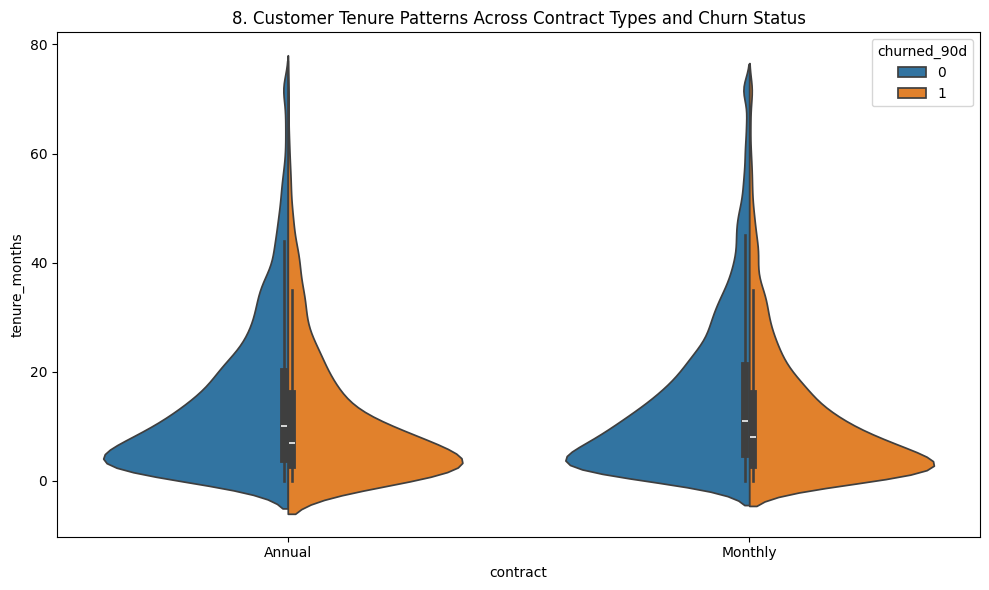

In [20]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='contract', y='tenure_months', hue='churned_90d', split=True)
plt.title(f'{plot_no}. Customer Tenure Patterns Across Contract Types and Churn Status')
show_fig()
plot_no += 1

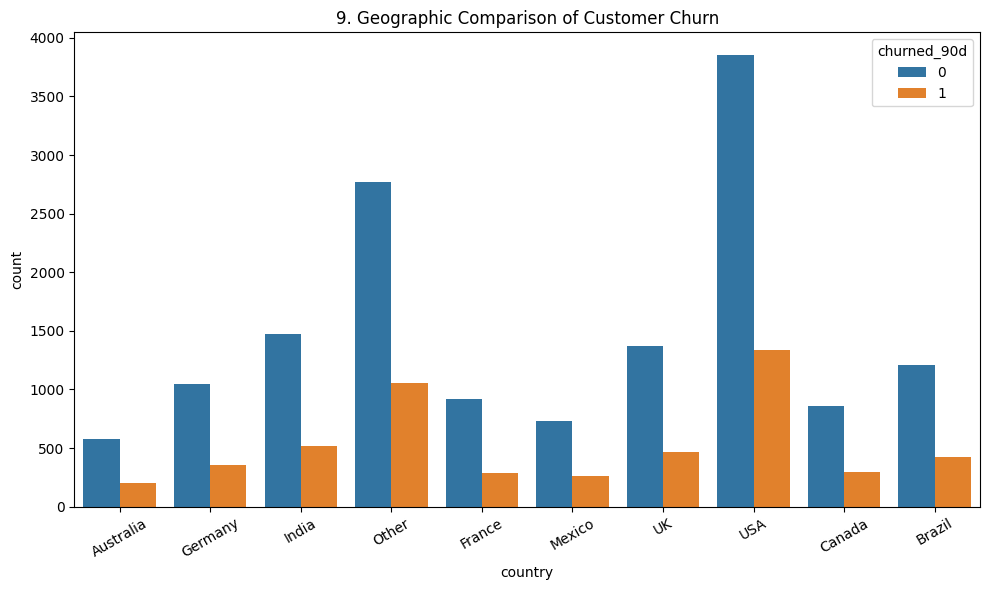

In [21]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='country', hue='churned_90d')
plt.title(f'{plot_no}. Geographic Comparison of Customer Churn')
plt.xticks(rotation=30)
show_fig()
plot_no += 1

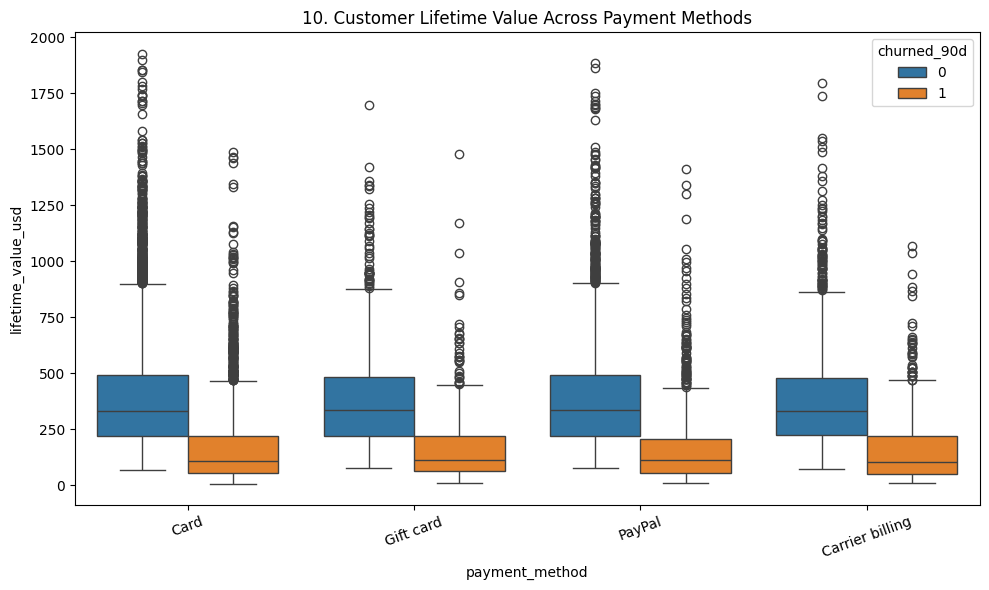

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='payment_method', y='lifetime_value_usd', hue='churned_90d')
plt.title(f'{plot_no}. Customer Lifetime Value Across Payment Methods')
plt.xticks(rotation=20)
show_fig()
plot_no += 1

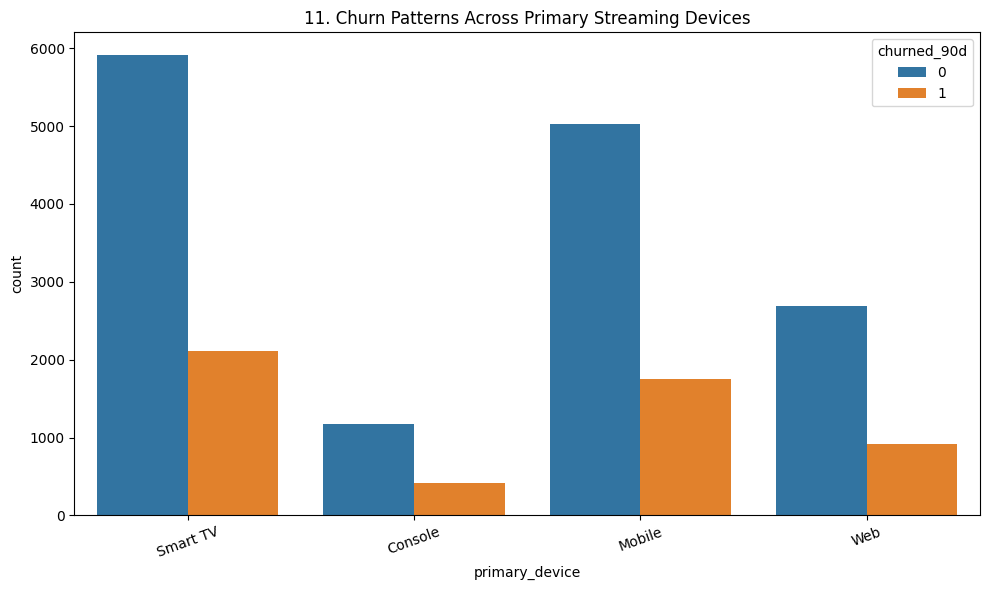

In [23]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='primary_device', hue='churned_90d')
plt.title(f'{plot_no}. Churn Patterns Across Primary Streaming Devices')
plt.xticks(rotation=20)
show_fig()
plot_no += 1

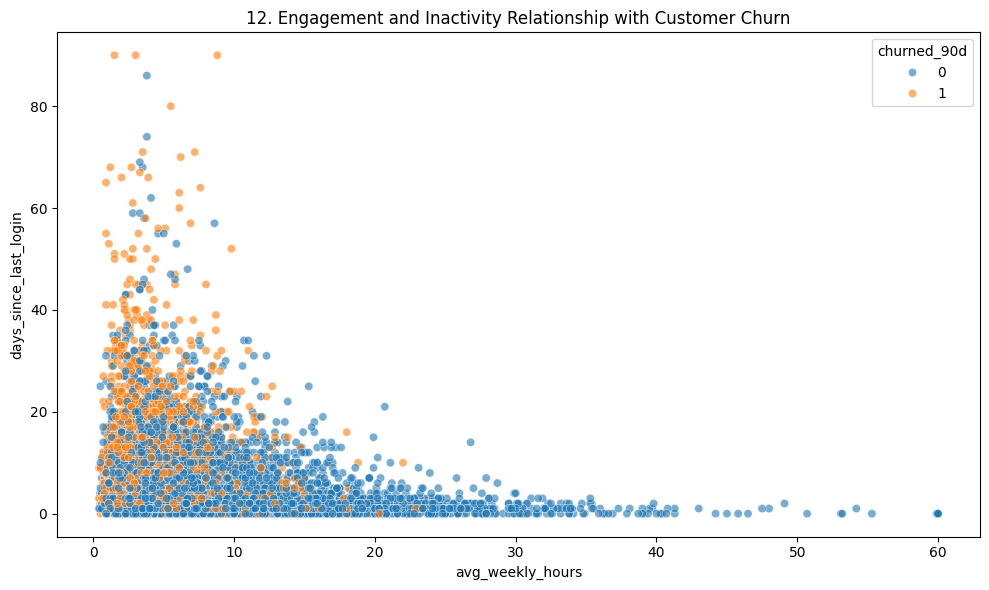

In [24]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='avg_weekly_hours', y='days_since_last_login', hue='churned_90d', alpha=0.6)
plt.title(f'{plot_no}. Engagement and Inactivity Relationship with Customer Churn')
show_fig()
plot_no += 1

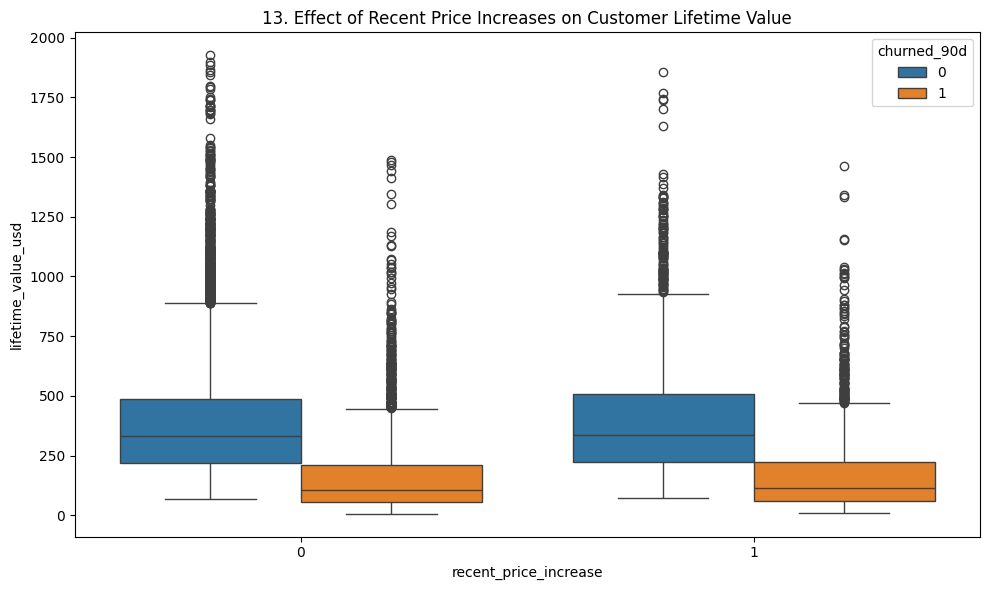

In [25]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='recent_price_increase', y='lifetime_value_usd', hue='churned_90d')
plt.title(f'{plot_no}. Effect of Recent Price Increases on Customer Lifetime Value')
show_fig()
plot_no += 1

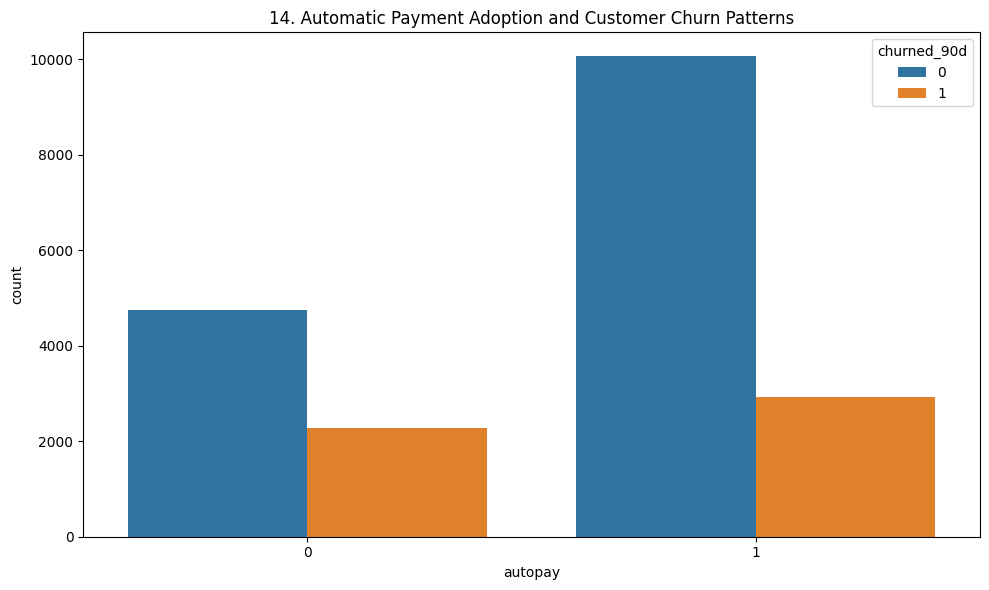

In [26]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='autopay', hue='churned_90d')
plt.title(f'{plot_no}. Automatic Payment Adoption and Customer Churn Patterns')
show_fig()
plot_no += 1

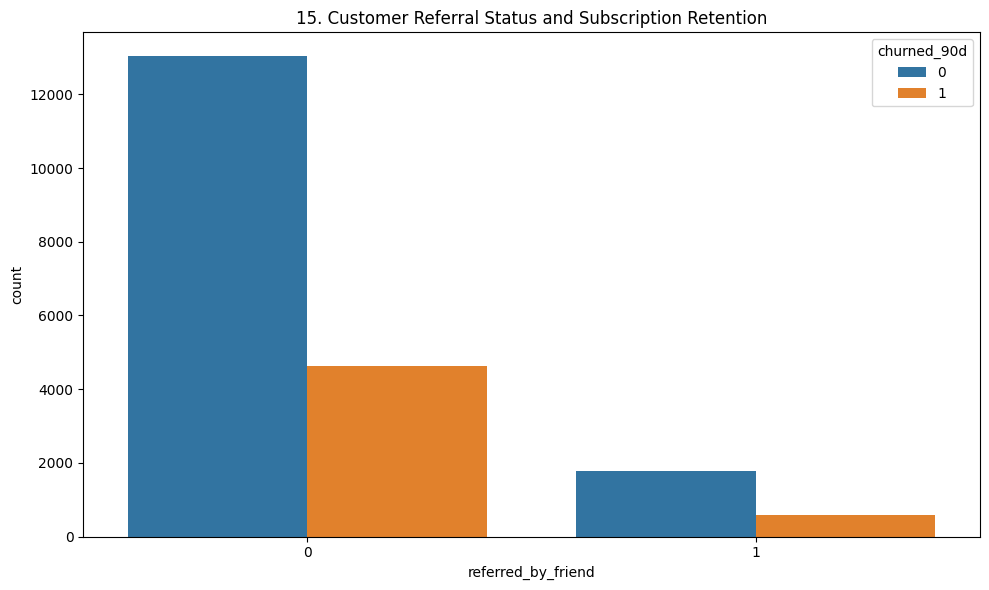

In [27]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='referred_by_friend', hue='churned_90d')
plt.title(f'{plot_no}. Customer Referral Status and Subscription Retention')
show_fig()
plot_no += 1

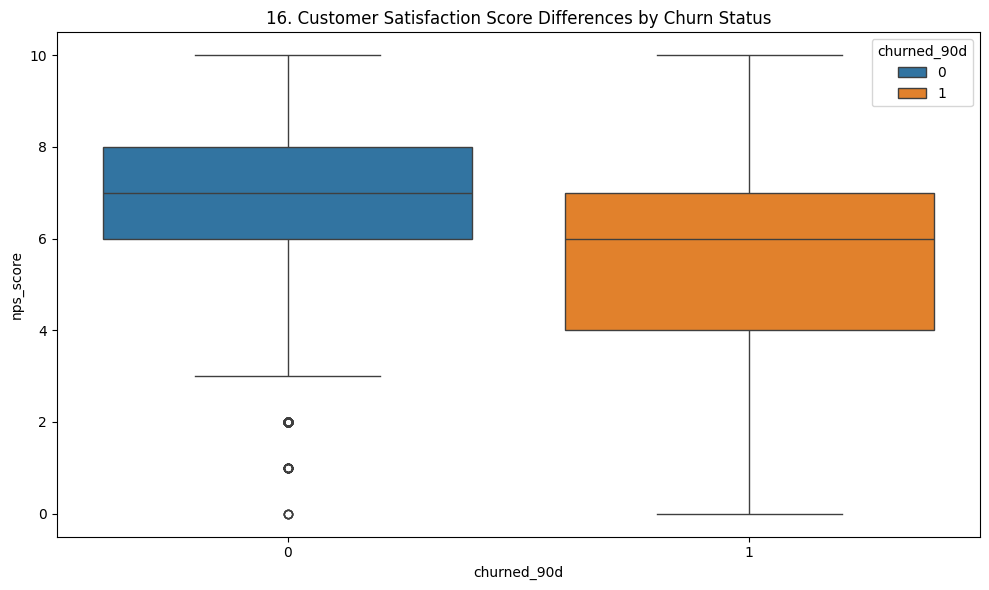

In [28]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='churned_90d', y='nps_score', hue='churned_90d')
plt.title(f'{plot_no}. Customer Satisfaction Score Differences by Churn Status')
show_fig()
plot_no += 1

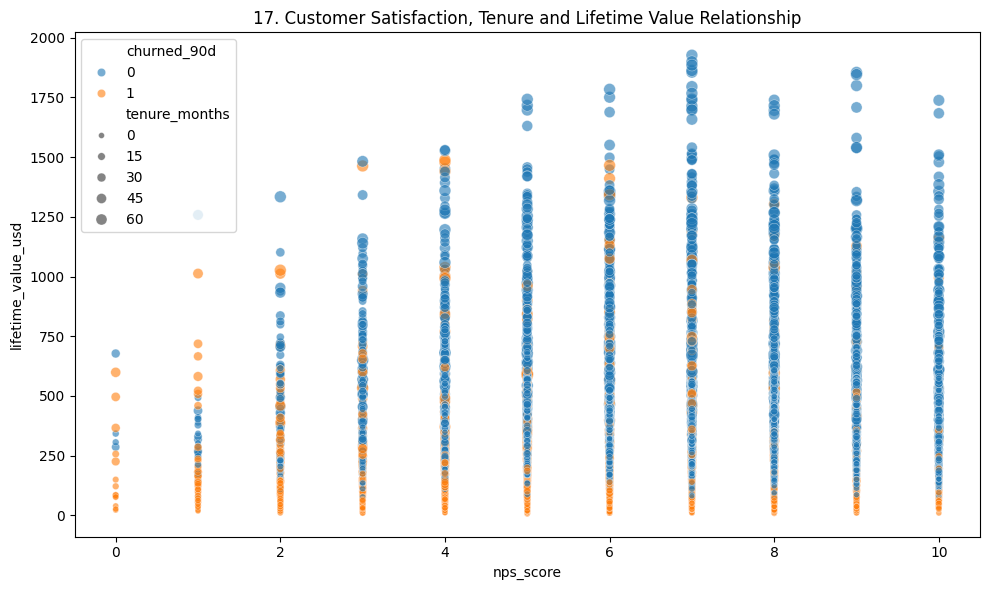

In [29]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='nps_score', y='lifetime_value_usd', hue='churned_90d', size='tenure_months', alpha=0.6)
plt.title(f'{plot_no}. Customer Satisfaction, Tenure and Lifetime Value Relationship')
show_fig()
plot_no += 1

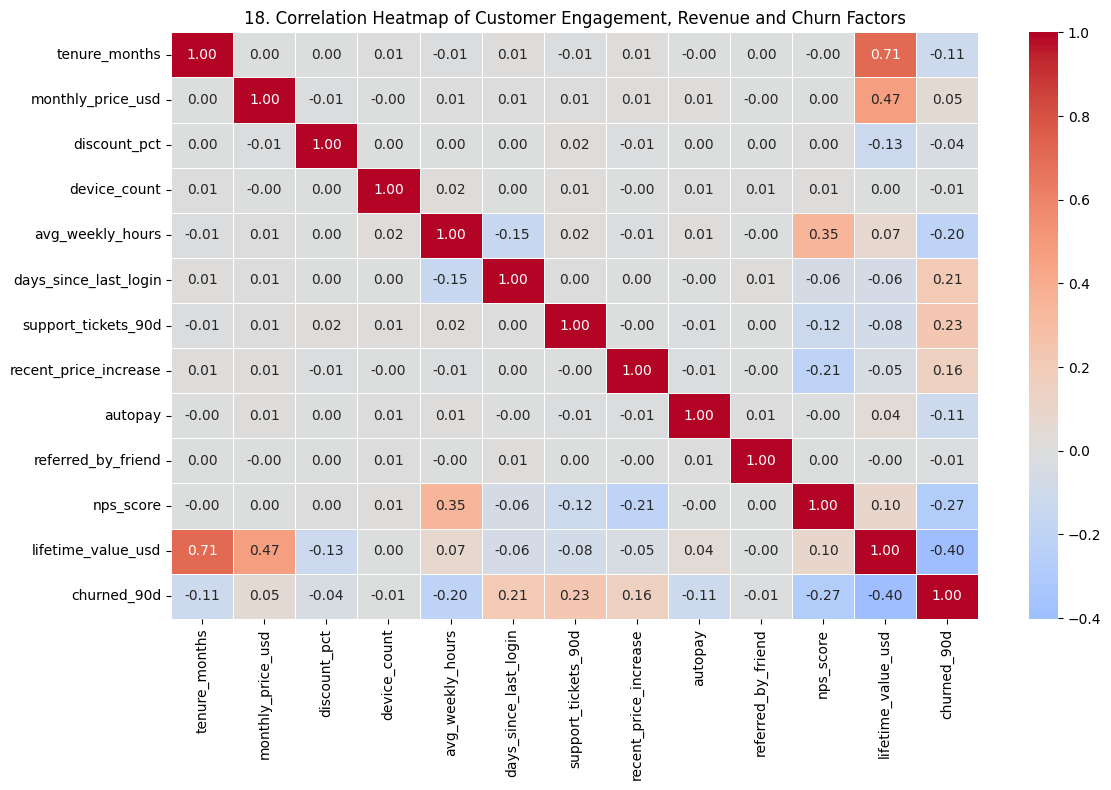

In [30]:
fig = plt.figure(figsize=(12,8))
corr = df.select_dtypes(include='number').drop(columns=['subscriber_id'], errors='ignore').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, center=0)
plt.title(f'{plot_no}. Correlation Heatmap of Customer Engagement, Revenue and Churn Factors')
show_fig()
plot_no += 1

# Model Training

## Separate features and target

In [31]:
X = df.drop(columns=['churned_90d', 'subscriber_id'], errors='ignore')
y = df['churned_90d']

## Identify numerical and categorical columns

In [32]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

## Preprocess numerical and categorical features

In [33]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

## Split training and testing data

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Create machine learning pipeline

In [35]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', HistGradientBoostingClassifier(
        random_state=42,
        class_weight='balanced',
        early_stopping=True
    ))
])

## Define hyperparameter search space

In [36]:
params = {
    'model__max_iter': [100, 200, 300, 400],
    'model__learning_rate': [0.03, 0.05, 0.08, 0.1],
    'model__max_leaf_nodes': [15, 20, 31, 40],
    'model__l2_regularization': [0.0, 0.1, 1.0, 5.0],
    'model__min_samples_leaf': [10, 20, 30, 50]
}

## Perform hyperparameter tuning

In [37]:
search = RandomizedSearchCV(
    pipeline,
    params,
    n_iter=15,
    scoring='roc_auc',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__l2_regularization': [0.0, 0.1, ...], 'model__learning_rate': [0.03, 0.05, ...], 'model__max_iter': [100, 200, ...], 'model__max_leaf_nodes': [15, 20, ...], ...}"
,n_iter,15
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


## Select best model

In [38]:
best_model = search.best_estimator_

## Generate predictions

In [39]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

## Evaluate model performance

In [40]:
print("Best Parameters:", search.best_params_)
print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Best Parameters: {'model__min_samples_leaf': 30, 'model__max_leaf_nodes': 15, 'model__max_iter': 400, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.1}

Accuracy: 0.9982
ROC-AUC Score: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      2960
           1       1.00      1.00      1.00      1040

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000



## Plot confusion matrix

<Figure size 1000x600 with 0 Axes>

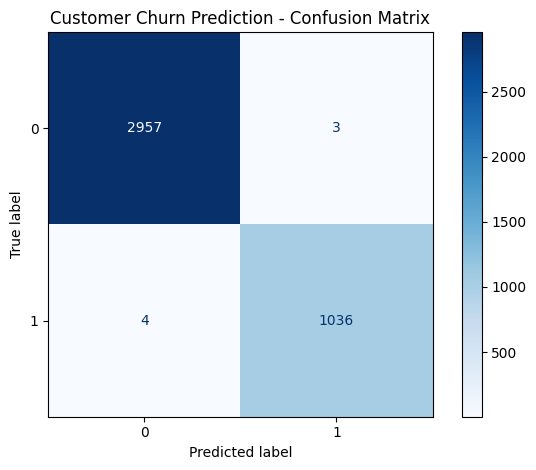

In [41]:
fig = plt.figure(figsize=(10,6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    cmap='Blues',
    values_format='d'
)
plt.title('Customer Churn Prediction - Confusion Matrix')
show_fig()

## Plot actual vs predicted churn distribution

<Figure size 1000x600 with 0 Axes>

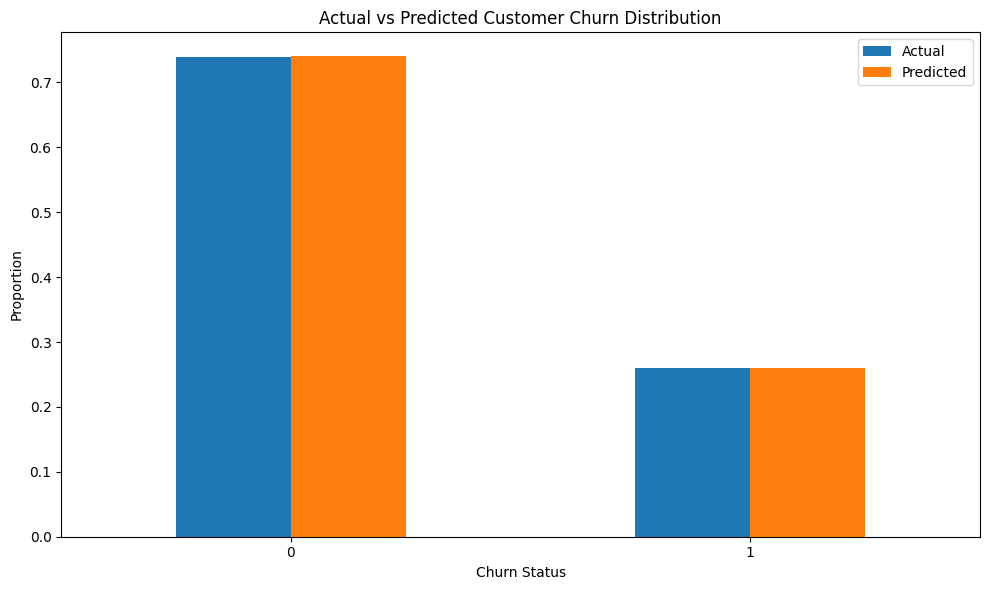

In [42]:
fig = plt.figure(figsize=(10,6))
comparison = pd.DataFrame({
    'Actual': y_test.value_counts(normalize=True),
    'Predicted': pd.Series(y_pred).value_counts(normalize=True)
}).fillna(0)

comparison.plot(kind='bar', figsize=(10,6))
plt.title('Actual vs Predicted Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Proportion')
plt.xticks(rotation=0)
show_fig()